In [6]:

# Practical 2: Classification Analysis using KNN

# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score
)

# 2. Load the dataset
df = pd.read_csv("Social_Network_Ads.csv")

print("First 5 rows:")
print(df.head())


First 5 rows:
    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0



Null values:
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Dataset Statistics:
            User ID         Age  EstimatedSalary   Purchased
count  4.000000e+02  400.000000       400.000000  400.000000
mean   1.569154e+07   37.655000     69742.500000    0.357500
std    7.165832e+04   10.482877     34096.960282    0.479864
min    1.556669e+07   18.000000     15000.000000    0.000000
25%    1.562676e+07   29.750000     43000.000000    0.000000
50%    1.569434e+07   37.000000     70000.000000    0.000000
75%    1.575036e+07   46.000000     88000.000000    1.000000
max    1.581524e+07   60.000000    150000.000000    1.000000

Shape before removing duplicates: (400, 4)
Shape after removing duplicates: (380, 4)

Updated dataset:
   Gender  Age  EstimatedSalary  Purchased
0       1   19            19000          0
1       1   35            20000          0
2       0   26            43000          0
3       0   27        

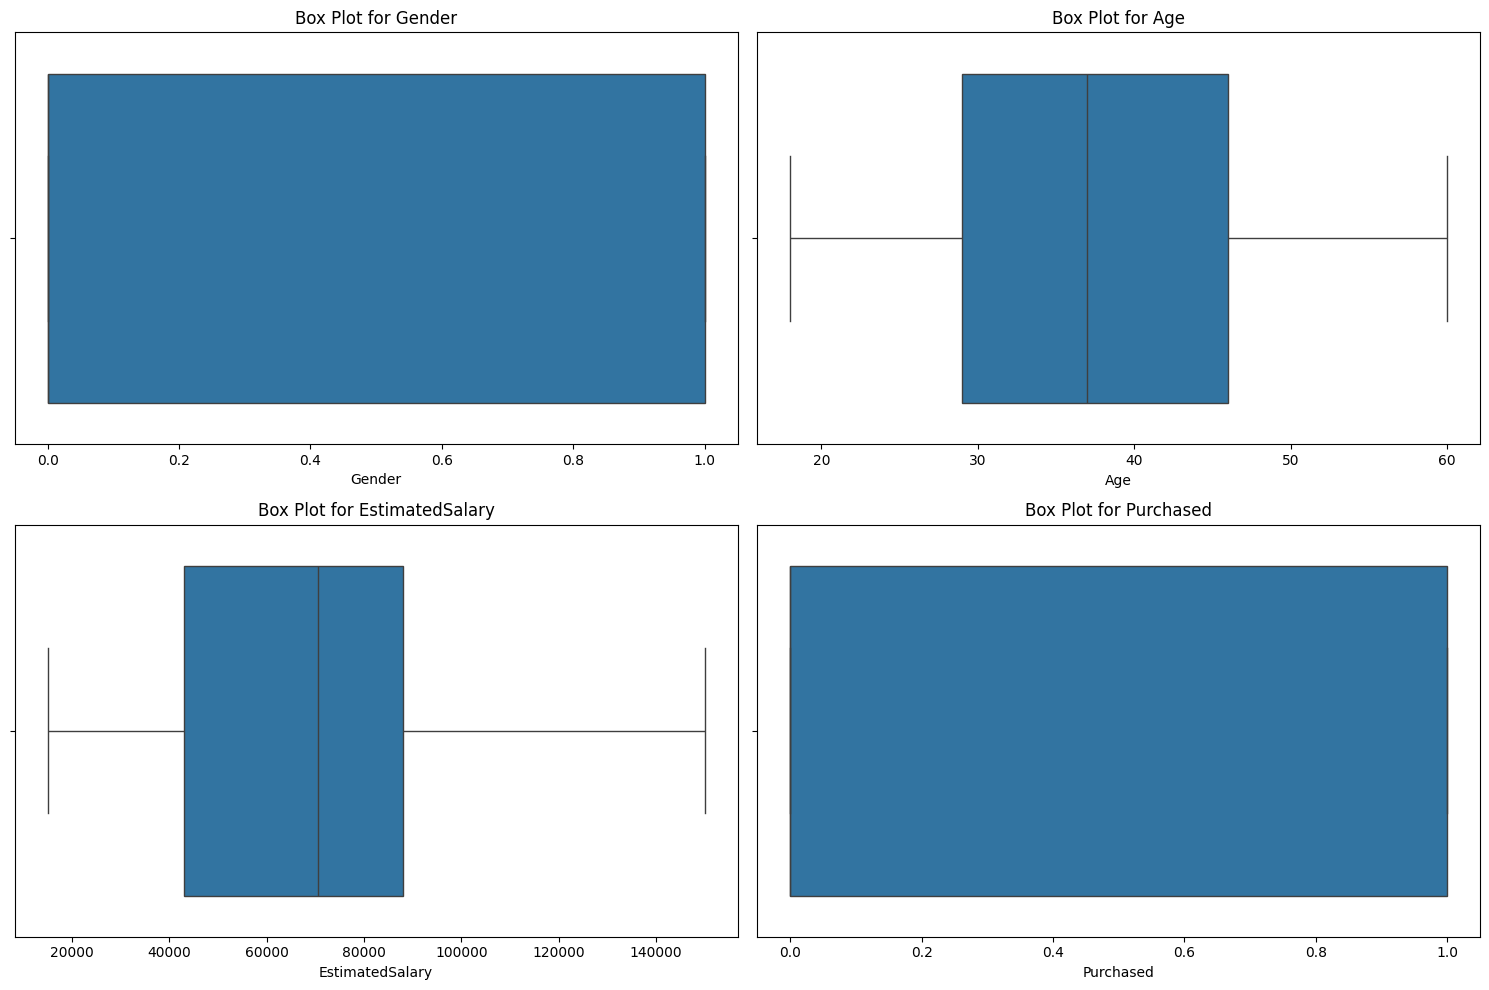

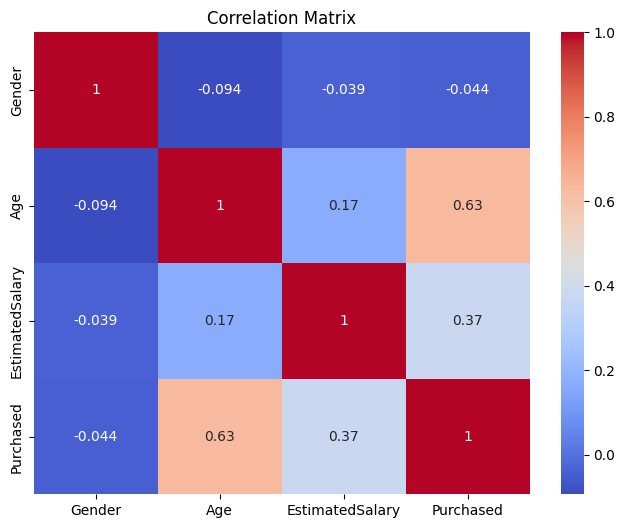


X_train shape: (285, 3)
X_test shape: (95, 3)
y_train shape: (285,)
y_test shape: (95,)

Accuracy: 0.88
Error Rate: 0.12
Precision: 0.82
Recall: 0.84

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.90      0.91        63
           1       0.82      0.84      0.83        32

    accuracy                           0.88        95
   macro avg       0.87      0.87      0.87        95
weighted avg       0.89      0.88      0.88        95

Confusion Matrix:
[[57  6]
 [ 5 27]]


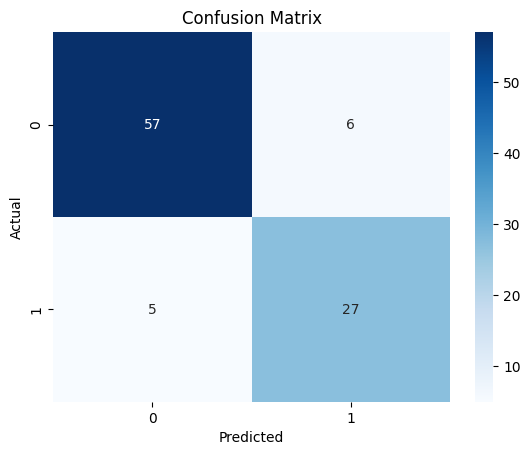

In [7]:


# 3. Identify null values
print("\nNull values:")
print(df.isnull().sum())

# Handle missing values
df = df.dropna()

# 4. Get initial statistics
print("\nDataset Statistics:")
print(df.describe())

# 5. Drop unnecessary column
df = df.drop(columns=['User ID'])

# 6. Remove duplicate records
print("\nShape before removing duplicates:", df.shape)

df = df.drop_duplicates(ignore_index=True)

print("Shape after removing duplicates:", df.shape)

# 7. Convert Gender into numerical values
df['Gender'] = df['Gender'].map({
    'Male': 1,
    'Female': 0
})

# Remove rows if gender conversion failed
df = df.dropna()

df['Gender'] = df['Gender'].astype(int)

print("\nUpdated dataset:")
print(df.head())

# 8. Detect outliers using box plots
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(
    df.select_dtypes(include=np.number).columns
):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(f'Box Plot for {col}')

plt.tight_layout()
plt.show()

# 9. Find correlation matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Matrix")
plt.show()

# 10. Prepare features and target
X = df.drop('Purchased', axis=1)
y = df['Purchased']

# 11. Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=0
)

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# 12. Apply StandardScaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 13. Train KNN model
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

# 14. Predict values
y_pred = knn.predict(X_test)

# 15. Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", round(accuracy, 2))

# 16. Calculate error rate
error_rate = 1 - accuracy

print("Error Rate:", round(error_rate, 2))

# 17. Calculate precision and recall
precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

print("Precision:", round(precision, 2))
print("Recall:", round(recall, 2))

# 18. Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 19. Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

